## Traditional Baseline Model (Dense Autoencoder)
Goal today: define a simple traditional model that compresses embeddings to a latent vector, adds AWGN noise, then reconstructs token logits over the sequence length.

In [17]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters (align with data prep)
vocab_size = 20000
pad_id = 0
max_len = 30
embed_dim = 128
encoder_hidden = [256, 128]
latent_dim = 64

def add_awgn(x: torch.Tensor, snr_db: float):
    """Additive white Gaussian noise at a given SNR (dB)."""
    snr_linear = 10 ** (snr_db / 10)
    dims = tuple(range(1, x.dim()))
    signal_power = x.pow(2).mean(dim=dims, keepdim=True)
    noise_power = signal_power / snr_linear
    noise_std = noise_power.sqrt()
    noise = torch.randn_like(x) * noise_std
    return x + noise

class TraditionalAutoencoder(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, encoder_hidden, latent_dim: int, max_len: int, pad_id: int = 0):
        super().__init__()
        self.pad_id = pad_id
        self.max_len = max_len
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_id)

        enc_layers = []
        in_dim = embed_dim
        for h in encoder_hidden:
            enc_layers += [nn.Linear(in_dim, h), nn.ReLU()]
            in_dim = h
        enc_layers += [nn.Linear(in_dim, latent_dim)]
        self.encoder = nn.Sequential(*enc_layers)

        # Decoder mirrors encoder but expands back to per-token representations
        dec_layers = [nn.Linear(latent_dim, encoder_hidden[-1]), nn.ReLU()]
        dec_layers += [nn.Linear(encoder_hidden[-1], encoder_hidden[0]), nn.ReLU()]
        dec_layers += [nn.Linear(encoder_hidden[0], max_len * embed_dim)]
        self.decoder = nn.Sequential(*dec_layers)

        self.output_layer = nn.Linear(embed_dim, vocab_size)

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor, snr_db: float = 6.0):
        # input_ids: (B, L), attention_mask: (B, L)
        emb = self.embedding(input_ids)  # (B, L, E)

        # Mask PAD tokens to zero, then mean-pool
        mask = attention_mask.unsqueeze(-1)  # (B, L, 1)
        emb_masked = emb * mask
        lengths = mask.sum(dim=1).clamp(min=1)  # (B, 1)
        pooled = emb_masked.sum(dim=1) / lengths  # (B, E)

        latent = self.encoder(pooled)            # (B, latent)
        latent_noisy = add_awgn(latent, snr_db)  # (B, latent)

        dec = self.decoder(latent_noisy)         # (B, L*E)
        dec = dec.view(-1, self.max_len, embed_dim)  # (B, L, E)

        logits = self.output_layer(dec)          # (B, L, vocab_size)
        return logits

# Instantiate model
model = TraditionalAutoencoder(
    vocab_size=vocab_size,
    embed_dim=embed_dim,
    encoder_hidden=encoder_hidden,
    latent_dim=latent_dim,
    max_len=max_len,
    pad_id=pad_id,
).to(device)

print(model)


TraditionalAutoencoder(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (encoder): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=3840, bias=True)
  )
  (output_layer): Linear(in_features=128, out_features=20000, bias=True)
)


In [18]:
# Sanity check with a fake batch
batch_size = 4
fake_input = torch.randint(low=1, high=vocab_size, size=(batch_size, max_len), device=device)
fake_mask = torch.ones_like(fake_input, device=device)

with torch.no_grad():
    logits = model(fake_input, fake_mask, snr_db=6.0)

print('Logits shape:', logits.shape)  # expected (B, L, vocab_size)


Logits shape: torch.Size([4, 30, 20000])


### Data prep (shared helper, local Europarl)
Use the shared loader with your local Europarl English files so vocabulary and splits stay consistent across notebooks.

In [19]:
from pathlib import Path
from data_prep import load_and_prepare, PAD, SOS, EOS, UNK

# Load Europarl directly from local files
EUROPARL_DIR = Path("europarl/text")
if not EUROPARL_DIR.exists():
    raise FileNotFoundError(f"Europarl directory not found: {EUROPARL_DIR.resolve()}")

dataset_encoded, vocab, stoi, itos, pad_id = load_and_prepare(
    max_len=max_len,
    max_vocab_size=vocab_size,
    min_freq=1,
    seed=42,
    dataset_name='europarl',
    europarl_local_dir=str(EUROPARL_DIR),
)

total_samples = sum(len(dataset_encoded[s]) for s in ['train', 'validation', 'test'])
print("Europarl dir:", EUROPARL_DIR.resolve())
print({split: len(dataset_encoded[split]) for split in dataset_encoded})
print("Total samples:", total_samples)
print("Vocab size:", len(vocab))
print("Sample encoded:", dataset_encoded["train"][0]["input_ids"][:15])

Filter:   0%|          | 0/1574113 [00:00<?, ? examples/s]

Map:   0%|          | 0/106348 [00:00<?, ? examples/s]

Map:   0%|          | 0/11817 [00:00<?, ? examples/s]

Map:   0%|          | 0/11817 [00:00<?, ? examples/s]

Europarl dir: D:\btp_reso\btp_env\europarl\text
{'train': 106348, 'validation': 11817, 'test': 11817}
Total samples: 129982
Vocab size: 20000
Sample encoded: [1, 88, 62, 9, 38, 41, 6, 198, 12, 46, 124, 4, 190, 5, 4]


In [20]:
# Europarl sanity check: sentence length, UNK ratio, and truncation estimate
eos_id = stoi[EOS]
unk_id = stoi[UNK]

def token_count_without_special(ids):
    n = 0
    for tok in ids:
        if tok == eos_id:
            break
        if tok not in {pad_id, stoi[SOS], stoi[EOS]}:
            n += 1
    return n

train_ids = [row['input_ids'] for row in dataset_encoded['train']]
num_tokens = 0
num_unk = 0
num_truncated_like = 0
lengths = []

for ids in train_ids:
    lengths.append(token_count_without_special(ids))
    for tok in ids:
        if tok in {pad_id, stoi[SOS], stoi[EOS]}:
            continue
        num_tokens += 1
        if tok == unk_id:
            num_unk += 1
    # Heuristic: sequence that reaches max_len and ends with EOS likely hit truncation path
    if ids[-1] == eos_id and pad_id not in ids:
        num_truncated_like += 1

avg_len = sum(lengths) / max(1, len(lengths))
unk_ratio = num_unk / max(1, num_tokens)
trunc_ratio = num_truncated_like / max(1, len(train_ids))

print("Europarl train sanity:")
print(f"  Avg tokens/sample: {avg_len:.2f}")
print(f"  UNK ratio: {unk_ratio:.4f}")
print(f"  Truncation-like ratio (heuristic): {trunc_ratio:.4f}")

Europarl train sanity:
  Avg tokens/sample: 16.41
  UNK ratio: 0.0039
  Truncation-like ratio (heuristic): 0.0436


In [21]:
from data_prep import get_dataloaders

loaders = get_dataloaders(dataset_encoded, pad_id=pad_id, batch_size=128)
batch = next(iter(loaders["train"]))
print({k: v.shape for k, v in batch.items()})

{'input_ids': torch.Size([128, 30]), 'attention_mask': torch.Size([128, 30])}


In [22]:
# Loss & optimizer
ignore_index = pad_id
criterion = nn.CrossEntropyLoss(ignore_index=ignore_index)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,                # Change to 1e-4
    betas=(0.9, 0.98),      # Add or update betas
    eps=1e-8,               # Add or update eps
    weight_decay=5e-4       # Add or update weight_decay
)


def train_one_epoch(model, loader, optimizer, criterion, snr_db: float):
    model.train()
    total_loss = 0.0
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        optimizer.zero_grad()
        logits = model(input_ids, attention_mask, snr_db=snr_db)
        loss = criterion(logits.view(-1, vocab_size), input_ids.view(-1))
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * input_ids.size(0)
    return total_loss / len(loader.dataset)


def evaluate_loss(model, loader, criterion, snr_db: float):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            logits = model(input_ids, attention_mask, snr_db=snr_db)
            loss = criterion(logits.view(-1, vocab_size), input_ids.view(-1))
            total_loss += loss.item() * input_ids.size(0)
    return total_loss / len(loader.dataset)


In [23]:
import numpy as np

In [42]:
# --- Robust checkpoint loading: model, losses, best_val ---
import os
import pickle

checkpoint_path = 'traditional_checkpoint.pkl'
if os.path.exists(checkpoint_path):
    with open(checkpoint_path, 'rb') as f:
        checkpoint = pickle.load(f)
    model.load_state_dict(checkpoint['model_state'])
    train_losses = checkpoint['train_losses']
    val_losses = checkpoint['val_losses']
    best_val = checkpoint['best_val']
    if 'optimizer_state' in checkpoint:
        optimizer.load_state_dict(checkpoint['optimizer_state'])
    else:
        print("No optimizer state found in checkpoint; optimizer will be reinitialized.")
    print(f"Loaded checkpoint. Previous best_val: {best_val:.4f}, epochs trained: {len(train_losses)}")
else:
    train_losses = []
    val_losses = []
    best_val = float('inf')
    print("No checkpoint found, starting fresh.")


Loaded checkpoint. Previous best_val: 4.8982, epochs trained: 181


In [41]:
# Training loop (DeepSC-aligned training setup)
num_epochs = 20
val_snr_db = 6.0

for epoch in range(1, num_epochs + 1):
    # Sample train SNR each epoch in [5, 10] dB (DeepSC-style)
    train_snr_db = np.random.uniform(5, 10)
    train_loss = train_one_epoch(model, loaders['train'], optimizer, criterion, snr_db=train_snr_db)
    val_loss = evaluate_loss(model, loaders['validation'], criterion, snr_db=val_snr_db)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Epoch {epoch}: train_snr={train_snr_db:.2f}dB  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")
    if val_loss < best_val:
        best_val = val_loss
        # Save full checkpoint (model, losses, best_val)
        checkpoint = {
            'model_state': model.state_dict(),
            'train_losses': train_losses,
            'val_losses': val_losses,
            'best_val': best_val,
            'optimizer_state': optimizer.state_dict(),  # Uncomment if you want optimizer resume
        }
        with open('traditional_checkpoint.pkl', 'wb') as f:
            pickle.dump(checkpoint, f)
        torch.save(model.state_dict(), 'traditional_best.pt')
        print("  Saved full checkpoint")


Epoch 1: train_snr=7.30dB  train_loss=4.7635  val_loss=4.9068
Epoch 2: train_snr=7.71dB  train_loss=4.7581  val_loss=4.9082
Epoch 3: train_snr=6.96dB  train_loss=4.7659  val_loss=4.9033
  Saved full checkpoint
Epoch 4: train_snr=6.54dB  train_loss=4.7703  val_loss=4.9042
Epoch 5: train_snr=9.98dB  train_loss=4.7392  val_loss=4.9081
Epoch 6: train_snr=7.25dB  train_loss=4.7608  val_loss=4.9027
  Saved full checkpoint
Epoch 7: train_snr=9.64dB  train_loss=4.7389  val_loss=4.9052
Epoch 8: train_snr=7.09dB  train_loss=4.7617  val_loss=4.9015
  Saved full checkpoint
Epoch 9: train_snr=5.80dB  train_loss=4.7782  val_loss=4.9003
  Saved full checkpoint
Epoch 10: train_snr=6.61dB  train_loss=4.7669  val_loss=4.9012
Epoch 11: train_snr=6.11dB  train_loss=4.7733  val_loss=4.9022
Epoch 12: train_snr=8.77dB  train_loss=4.7450  val_loss=4.9029
Epoch 13: train_snr=9.99dB  train_loss=4.7332  val_loss=4.9067
Epoch 14: train_snr=6.72dB  train_loss=4.7642  val_loss=4.8986
  Saved full checkpoint
Epoch 1

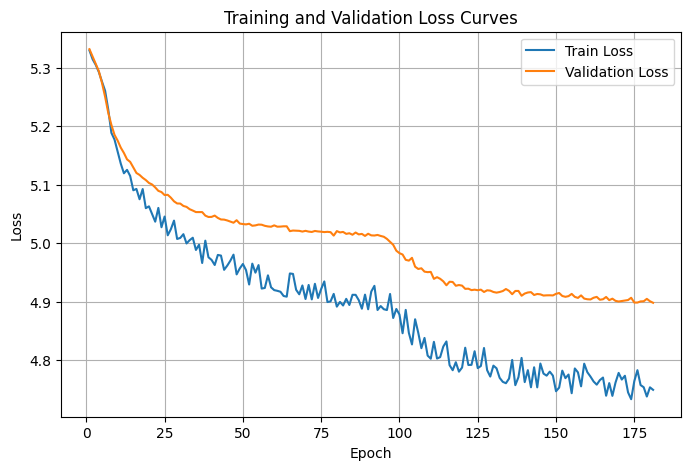

In [43]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.grid(True)
plt.show()

In [44]:
import nltk
from nltk.translate.bleu_score import sentence_bleu

special_ids = {pad_id, stoi[SOS], stoi[EOS], stoi[UNK]}

def decode_tokens(id_list):
    toks = []
    for i in id_list:
        if i == stoi[EOS]:
            break
        if i in special_ids:
            continue
        toks.append(itos.get(i, UNK))
    return ' '.join(toks)


def eval_bleu_all(model, loader, snr_db: float, max_batches: int = 50):
    model.eval()
    scores_1, scores_2, scores_3, scores_4 = [], [], [], []
    count = 0
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            logits = model(input_ids, attention_mask, snr_db=snr_db)
            preds = logits.argmax(dim=-1).cpu().tolist()
            truths = input_ids.cpu().tolist()
            for p, t in zip(preds, truths):
                hyp = decode_tokens(p)
                ref = decode_tokens(t)
                if len(ref.split()) == 0:
                    continue
                ref_tokens = [ref.split()]
                hyp_tokens = hyp.split()
                scores_1.append(sentence_bleu(ref_tokens, hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=None))
                scores_2.append(sentence_bleu(ref_tokens, hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=None))
                scores_3.append(sentence_bleu(ref_tokens, hyp_tokens, weights=(1/3, 1/3, 1/3, 0), smoothing_function=None))
                scores_4.append(sentence_bleu(ref_tokens, hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None))
            count += 1
            if count >= max_batches:
                break
    return {
        'bleu1': sum(scores_1) / len(scores_1) if scores_1 else 0.0,
        'bleu2': sum(scores_2) / len(scores_2) if scores_2 else 0.0,
        'bleu3': sum(scores_3) / len(scores_3) if scores_3 else 0.0,
        'bleu4': sum(scores_4) / len(scores_4) if scores_4 else 0.0,
    }


### Traditional model readiness checklist (Europarl)
- Data prep: load/clean/encode local Europarl English files ✅
- Dataloaders with masks ✅
- Model: embedding → dense encoder → AWGN → dense decoder → vocab logits ✅
- Loss/optimizer: CrossEntropy (ignore PAD), Adam ✅
- Training loop scaffold ✅
- BLEU evaluation + SNR sweep helpers ✅
- Qualitative reconstructions helper ✅

Next steps to run:
1) Confirm the Europarl directory printout and split sizes from the data cell.
2) Run the Europarl sanity cell and check UNK/truncation ratios are reasonable.
3) Increase `num_epochs` (e.g., 10–20) and run the training cell.
4) Run `show_reconstructions` and `snr_sweep(model, loaders['validation'], snr_values=[-6,-3,0,3,6,9,12])`.
5) Save results/plots for the report.

### Qualitative: multiple validation samples across SNRs
Check the best checkpoint on several non-trivial sentences and see how noise affects reconstructions.

### Plot BLEU vs SNR
Create a simple line plot (and save it) after running the full sweep.

In [45]:
import json
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd

snr_values = [0, 3, 6, 9, 12, 15, 18]
max_eval_batches = 50
checkpoint_path = Path('traditional_best.pt')

if not checkpoint_path.exists():
    raise FileNotFoundError('traditional_best.pt not found. Train first, then rerun this cell.')

# Always evaluate from the saved best checkpoint for reproducibility
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.to(device)
model.eval()

print('Running full traditional SNR sweep...')
results_latest = {snr: eval_bleu_all(model, loaders['test'], snr_db=snr, max_batches=max_eval_batches) for snr in snr_values}

# Save results to JSON
payload = {
    'model': 'traditional_autoencoder',
    'checkpoint': str(checkpoint_path),
    'generated_at_utc': datetime.now(timezone.utc).isoformat(),
    'max_eval_batches': max_eval_batches,
    'snr_values': snr_values,
    'bleu_by_snr': {str(k): v for k, v in sorted(results_latest.items())},
}
json_path = Path('traditional_results_latest.json')
json_path.write_text(json.dumps(payload, indent=2), encoding='utf-8')

# Save results to CSV (BLEU-1/2/3/4 for each SNR)
rows = []
for snr in snr_values:
    row = {'snr_db': snr}
    row.update(results_latest[snr])
    rows.append(row)
df = pd.DataFrame(rows)
csv_path = Path('traditional_results_latest.csv')
df.to_csv(csv_path, index=False)

print(f'Saved: {json_path}')
print(f'Saved: {csv_path}')

C:\Users\YASH KULKARNI\AppData\Local\Temp\ipykernel_26180\1516878215.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint_path, m

Running full traditional SNR sweep...
Saved: traditional_results_latest.json
Saved: traditional_results_latest.csv


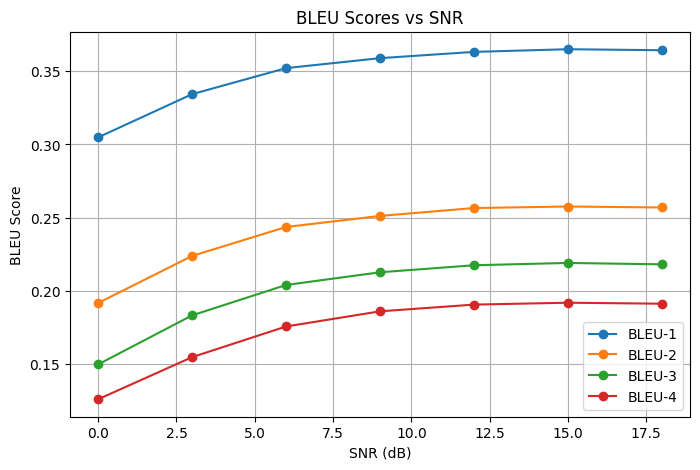

In [47]:
import matplotlib.pyplot as plt

snr_values = sorted(results_latest.keys())
bleu1 = [results_latest[snr]['bleu1'] for snr in snr_values]
bleu2 = [results_latest[snr]['bleu2'] for snr in snr_values]
bleu3 = [results_latest[snr]['bleu3'] for snr in snr_values]
bleu4 = [results_latest[snr]['bleu4'] for snr in snr_values]

plt.figure(figsize=(8, 5))
plt.plot(snr_values, bleu1, marker='o', label='BLEU-1')
plt.plot(snr_values, bleu2, marker='o', label='BLEU-2')
plt.plot(snr_values, bleu3, marker='o', label='BLEU-3')
plt.plot(snr_values, bleu4, marker='o', label='BLEU-4')
plt.xlabel('SNR (dB)')
plt.ylabel('BLEU Score')
plt.title('BLEU Scores vs SNR')
plt.legend()
plt.grid(True)
plt.show()

C:\Users\YASH KULKARNI\AppData\Local\Temp\ipykernel_26180\3811109734.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('traditional_best.p

BLEU-1 - Mean: 0.3480, Median: 0.1998, Zeros: 565 / 11816
BLEU-2 - Mean: 0.2387, Median: 0.0000, Zeros: 565 / 11816
BLEU-3 - Mean: 0.1979, Median: 0.0000, Zeros: 565 / 11816
BLEU-4 - Mean: 0.1714, Median: 0.0000, Zeros: 565 / 11816


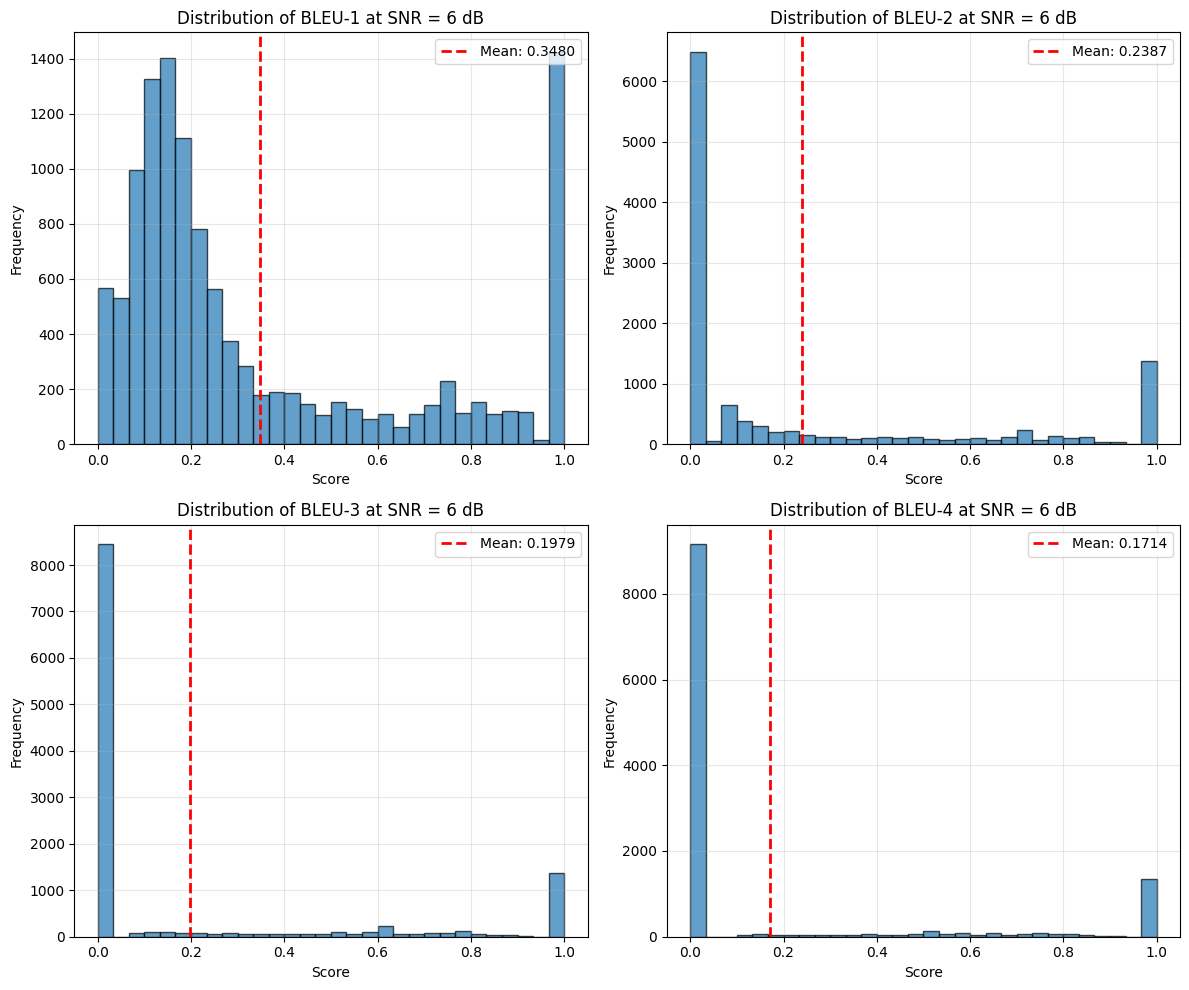

In [49]:
import matplotlib.pyplot as plt
import numpy as np

# Collect all BLEU scores for all samples at SNR = 6 dB
snr_to_analyze = 6
model.load_state_dict(torch.load('traditional_best.pt', map_location=device))
model.to(device)
model.eval()

bleu1_scores = []
bleu2_scores = []
bleu3_scores = []
bleu4_scores = []

with torch.no_grad():
    for batch in loaders['test']:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        logits = model(input_ids, attention_mask, snr_db=snr_to_analyze)
        preds = logits.argmax(dim=-1).cpu().tolist()
        truths = input_ids.cpu().tolist()
        
        for p, t in zip(preds, truths):
            hyp = decode_tokens(p)
            ref = decode_tokens(t)
            if len(ref.split()) == 0:
                continue
            ref_tokens = [ref.split()]
            hyp_tokens = hyp.split()
            
            bleu1_scores.append(sentence_bleu(ref_tokens, hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=None))
            bleu2_scores.append(sentence_bleu(ref_tokens, hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=None))
            bleu3_scores.append(sentence_bleu(ref_tokens, hyp_tokens, weights=(1/3, 1/3, 1/3, 0), smoothing_function=None))
            bleu4_scores.append(sentence_bleu(ref_tokens, hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None))

# Plot histograms side by side
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

scores_list = [bleu1_scores, bleu2_scores, bleu3_scores, bleu4_scores]
labels = ['BLEU-1', 'BLEU-2', 'BLEU-3', 'BLEU-4']
axes_flat = axes.flatten()

for idx, (scores, label, ax) in enumerate(zip(scores_list, labels, axes_flat)):
    ax.hist(scores, bins=30, edgecolor='black', alpha=0.7)
    ax.set_xlabel('Score')
    ax.set_ylabel('Frequency')
    ax.set_title(f'Distribution of {label} at SNR = {snr_to_analyze} dB')
    ax.axvline(np.mean(scores), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(scores):.4f}')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Print statistics
    print(f"{label} - Mean: {np.mean(scores):.4f}, Median: {np.median(scores):.4f}, Zeros: {sum(1 for s in scores if s == 0)} / {len(scores)}")

plt.tight_layout()
plt.show()

In [51]:
import torch
import pandas as pd
from nltk.translate.bleu_score import sentence_bleu

snr_values = [0, 3, 6, 9, 12, 15, 18]
model.load_state_dict(torch.load('traditional_best.pt', map_location=device))
model.to(device)
model.eval()

# Collect all results with BLEU scores
all_results = []

with torch.no_grad():
    for batch in loaders['test']:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        
        for batch_idx in range(input_ids.shape[0]):
            inp = input_ids[batch_idx:batch_idx+1]
            mask = attention_mask[batch_idx:batch_idx+1]
            ref = decode_tokens(inp[0].cpu().tolist())
            
            if len(ref.split()) == 0:
                continue
            
            row = {'reference': ref}
            max_bleu4 = 0
            best_snr = None
            
            for snr in snr_values:
                logits = model(inp, mask, snr_db=snr)
                pred_ids = logits.argmax(dim=-1).cpu().squeeze(0).tolist()
                hyp = decode_tokens(pred_ids)
                
                ref_tokens = [ref.split()]
                hyp_tokens = hyp.split()
                
                bleu1 = sentence_bleu(ref_tokens, hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=None)
                bleu2 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=None)
                bleu3 = sentence_bleu(ref_tokens, hyp_tokens, weights=(1/3, 1/3, 1/3, 0), smoothing_function=None)
                bleu4 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None)
                
                row[f'hyp_{snr}'] = hyp
                row[f'bleu1_{snr}'] = bleu1
                row[f'bleu2_{snr}'] = bleu2
                row[f'bleu3_{snr}'] = bleu3
                row[f'bleu4_{snr}'] = bleu4
                
                if bleu4 > max_bleu4:
                    max_bleu4 = bleu4
                    best_snr = snr
            
            row['max_bleu4'] = max_bleu4
            row['best_snr'] = best_snr
            all_results.append(row)

# Create DataFrame and sort by BLEU-4 score
results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values('max_bleu4', ascending=False)

# Print top 20 best reconstructions
print("=" * 100)
print("TOP 20 BEST RECONSTRUCTIONS (by BLEU-4)")
print("=" * 100)

for idx, row in results_df.head(20).iterrows():
    print(f"\nRank {results_df.index.get_loc(idx) + 1}")
    print(f"Best BLEU-4: {row['max_bleu4']:.4f} at SNR {int(row['best_snr'])} dB")
    print(f"Reference: {row['reference']}")
    
    best_snr = int(row['best_snr'])
    print(f"BLEU Scores at SNR {best_snr} dB:")
    print(f"  BLEU-1: {row[f'bleu1_{best_snr}']:.4f}")
    print(f"  BLEU-2: {row[f'bleu2_{best_snr}']:.4f}")
    print(f"  BLEU-3: {row[f'bleu3_{best_snr}']:.4f}")
    print(f"  BLEU-4: {row[f'bleu4_{best_snr}']:.4f}")
    print(f"Hypothesis: {row[f'hyp_{best_snr}']}")
    print("-" * 100)

C:\Users\YASH KULKARNI\AppData\Local\Temp\ipykernel_26180\2464004509.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('traditional_best.p

TOP 20 BEST RECONSTRUCTIONS (by BLEU-4)

Rank 1
Best BLEU-4: 1.0000 at SNR 15 dB
Reference: the president declared the common position approved as amended
BLEU Scores at SNR 15 dB:
  BLEU-1: 1.0000
  BLEU-2: 1.0000
  BLEU-3: 1.0000
  BLEU-4: 1.0000
Hypothesis: the president declared the common position approved as amended
----------------------------------------------------------------------------------------------------

Rank 2
Best BLEU-4: 1.0000 at SNR 0 dB
Reference: thank you very much commissioner
BLEU Scores at SNR 0 dB:
  BLEU-1: 1.0000
  BLEU-2: 1.0000
  BLEU-3: 1.0000
  BLEU-4: 1.0000
Hypothesis: thank you very much commissioner
----------------------------------------------------------------------------------------------------

Rank 3
Best BLEU-4: 1.0000 at SNR 3 dB
Reference: the minutes were approved
BLEU Scores at SNR 3 dB:
  BLEU-1: 1.0000
  BLEU-2: 1.0000
  BLEU-3: 1.0000
  BLEU-4: 1.0000
Hypothesis: the minutes were approved
--------------------------------------------

In [52]:
# Filter results where max_bleu4 is between 0.3 and 0.4
filtered_df = results_df[(results_df['max_bleu4'] >= 0.3) & (results_df['max_bleu4'] <= 0.4)]

print("=" * 100)
print(f"RECONSTRUCTIONS WITH BLEU-4 BETWEEN 0.3 AND 0.4 ({len(filtered_df)} samples)")
print("=" * 100)

for idx, row in filtered_df.iterrows():
    print(f"\nBLEU-4: {row['max_bleu4']:.4f} at SNR {int(row['best_snr'])} dB")
    print(f"Reference: {row['reference']}")
    
    best_snr = int(row['best_snr'])
    print(f"BLEU Scores at SNR {best_snr} dB:")
    print(f"  BLEU-1: {row[f'bleu1_{best_snr}']:.4f}")
    print(f"  BLEU-2: {row[f'bleu2_{best_snr}']:.4f}")
    print(f"  BLEU-3: {row[f'bleu3_{best_snr}']:.4f}")
    print(f"  BLEU-4: {row[f'bleu4_{best_snr}']:.4f}")
    print(f"Hypothesis: {row[f'hyp_{best_snr}']}")
    print("-" * 100)

RECONSTRUCTIONS WITH BLEU-4 BETWEEN 0.3 AND 0.4 (139 samples)

BLEU-4: 0.3994 at SNR 9 dB
Reference: the president declared the two common positions approved as amended
BLEU Scores at SNR 9 dB:
  BLEU-1: 0.7954
  BLEU-2: 0.6670
  BLEU-3: 0.5546
  BLEU-4: 0.3994
Hypothesis: the president declared the common position approved as amended
----------------------------------------------------------------------------------------------------

BLEU-4: 0.3983 at SNR 9 dB
Reference: i have received five motions for resolutions tabled pursuant to rule 37 2
BLEU Scores at SNR 9 dB:
  BLEU-1: 0.6923
  BLEU-2: 0.5883
  BLEU-3: 0.5012
  BLEU-4: 0.3983
Hypothesis: i have received six motions for resolutions tabled pursuant rule rule rule of
----------------------------------------------------------------------------------------------------

BLEU-4: 0.3958 at SNR 9 dB
Reference: the next item is the statements from the council and the commission on the members statute
BLEU Scores at SNR 9 dB:
  BLEU-1: 

In [54]:
import numpy as np

# Assumes results_df from your previous cell already exists
# results_df columns used:
# - reference, max_bleu4, best_snr
# - hyp_{snr}, bleu1_{snr}, bleu2_{snr}, bleu3_{snr}, bleu4_{snr}

snr_values = [0, 3, 6, 9, 12, 15, 18]
targets = [round(x, 1) for x in np.arange(0.1, 1.01, 0.1)]  # 0.1 ... 1.0

selected_rows = []
used_indices = set()

for t in targets:
    # pick row with max_bleu4 closest to target t, while avoiding duplicates
    candidates = results_df.loc[~results_df.index.isin(used_indices)].copy()
    if candidates.empty:
        break

    candidates["dist_to_target"] = (candidates["max_bleu4"] - t).abs()
    best_idx = candidates["dist_to_target"].idxmin()

    selected_rows.append((t, best_idx, results_df.loc[best_idx]))
    used_indices.add(best_idx)

print("=" * 120)
print("10 SAMPLES : TARGET BLEU-4 SCORE (0.1 to 1.0)")
print("=" * 120)

for rank, (target, idx, row) in enumerate(selected_rows, start=1):
    print(f"\nSample {rank} | target BLEU-4={target:.1f} | selected max_bleu4={row['max_bleu4']:.4f} | best_snr={int(row['best_snr'])} dB")
    print(f"Reference: {row['reference']}")
    print("-" * 120)
    print("All SNR reconstructions:")
    for snr in snr_values:
        print(
            f"SNR {snr:>2} dB | "
            f"B1={row[f'bleu1_{snr}']:.4f}  "
            f"B2={row[f'bleu2_{snr}']:.4f}  "
            f"B3={row[f'bleu3_{snr}']:.4f}  "
            f"B4={row[f'bleu4_{snr}']:.4f}"
        )
        print(f"HYP: {row[f'hyp_{snr}']}")
    print("=" * 120)

10 SAMPLES : TARGET BLEU-4 SCORE (0.1 to 1.0)

Sample 1 | target BLEU-4=0.1 | selected max_bleu4=0.0996 | best_snr=0 dB
Reference: thank you very much for this excellent report we look forward very much to working with the rapporteur and the parliament and to further progress on this issue
------------------------------------------------------------------------------------------------------------------------
All SNR reconstructions:
SNR  0 dB | B1=0.2849  B2=0.1779  B3=0.1347  B4=0.0996
HYP: thank you very much thank you i the you you to to to to the the the to to the to to you to to to
SNR  3 dB | B1=0.2493  B2=0.0961  B3=0.0000  B4=0.0000
HYP: thank you mr much mr you you the you you to to to to the the the to to the to to you to to to
SNR  6 dB | B1=0.2483  B2=0.0958  B3=0.0000  B4=0.0000
HYP: thank you i much i you you you you you to to i i i the you to to the to to you to to
SNR  9 dB | B1=0.1781  B2=0.0000  B3=0.0000  B4=0.0000
HYP: thank president i i thank thank i the to the to